# Accessmath official annotation EDA

Target: whiteboard keyframe / required-state qualification. Released annotations are for extractive lecture summaries; keyframe images alone do not establish required-state ground truth. Original source video links are inspected but the videos are not fetched.

Source: https://www.cs.rit.edu/~rlaz/files/tangent-v/AccessMath_ICDAR_2017_data.zip

This run reads **all released annotation XML and keyframe PNG filenames**, decodes **all keyframe PNGs for perceptual-hash screening**, displays a deterministic **one-image-per-split gallery**, and does **not** download original videos. Near-hash pairs are review candidates, not automatic exclusions. It inspects testing annotations, so that split cannot later be called unseen. ZIP is read in place (no unsafe extraction).

In [1]:
SOURCE_URL = 'https://www.cs.rit.edu/~rlaz/files/tangent-v/AccessMath_ICDAR_2017_data.zip'
ARCHIVE_NAME = 'accessmath-official-2017.zip'
EXPECTED_SHA256 = '7bffabf04ecf5ee5c03fb36089dba81bbef8c6a0f310002207df6ed51bfd9fee'
import hashlib, io, json, os, urllib.request, zipfile
from collections import Counter, defaultdict
from pathlib import Path, PurePosixPath
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import display

def cache_root():
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "experiments" / "notebooks").is_dir() and (root / "README.md").exists():
            p = root / "experiments" / "outputs" / "board_eda_downloads"
            p.mkdir(parents=True, exist_ok=True)
            return p
    p = Path.cwd() / "board_eda_downloads"
    p.mkdir(parents=True, exist_ok=True)
    return p

def download(url, target, max_bytes=800_000_000):
    if target.exists() and target.stat().st_size > 0:
        return target
    tmp = target.with_suffix(target.suffix + ".part")
    try:
        with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "lecture-eda/1.0"}), timeout=90) as response, tmp.open("wb") as out:
            total = 0
            while block := response.read(1024 * 1024):
                total += len(block)
                if total > max_bytes:
                    raise ValueError(f"Download exceeds declared limit: {url}")
                out.write(block)
        if tmp.stat().st_size < 100:
            raise ValueError(f"Too small to be dataset archive: {url}")
        tmp.replace(target)
    finally:
        tmp.unlink(missing_ok=True)
    return target

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def checked_zip(path):
    archive = zipfile.ZipFile(path)
    entries = archive.infolist()
    for item in entries:
        name = item.filename.replace("\\", "/")
        parts = PurePosixPath(name).parts
        if name.startswith("/") or ".." in parts or (parts and ":" in parts[0]):
            raise ValueError(f"Unsafe archive member: {item.filename}")
    bad = archive.testzip()
    if bad:
        raise ValueError(f"CRC failed: {bad}")
    actual_sha256 = sha256_file(path)
    if actual_sha256 != EXPECTED_SHA256:
        raise ValueError(f"Archive SHA-256 differs from pinned author release: {actual_sha256}")
    print(json.dumps({"url": SOURCE_URL, "archive_bytes": path.stat().st_size, "sha256": actual_sha256, "members": len(entries), "crc": "ok"}, indent=2))
    return archive

CACHE = cache_root()
ARCHIVE_PATH = download(SOURCE_URL, CACHE / ARCHIVE_NAME)
ZIP = checked_zip(ARCHIVE_PATH)
NAMES = set(ZIP.namelist())


{
  "url": "https://www.cs.rit.edu/~rlaz/files/tangent-v/AccessMath_ICDAR_2017_data.zip",
  "archive_bytes": 236610823,
  "sha256": "7bffabf04ecf5ee5c03fb36089dba81bbef8c6a0f310002207df6ed51bfd9fee",
  "members": 1521,
  "crc": "ok"
}


In [2]:
def xml_member(name): return ET.fromstring(ZIP.read(name))
DB = xml_member(next(p for p in NAMES if p.endswith("/db_AccessMath2015.xml")))
EDITED = {}
def is_primary_xml(p):
    return "/data/annotations/AccessMath2015_" in p and p.endswith(".xml") and PurePosixPath(p).parent.name == "annotations"
def annotation_id(p): return PurePosixPath(p).stem.removeprefix("AccessMath2015_")
def annotation_prefix(lecture_id): return next(p[:-4] for p in NAMES if is_primary_xml(p) and annotation_id(p) == lecture_id)

def xml_member(name):
    return ET.fromstring(ZIP.read(name))

def to_int(text):
    try:
        return int(float(text))
    except (TypeError, ValueError):
        return None

split_members = {}
for section in ["Training", "Testing", "Validation"]:
    split_members[section.lower()] = {x.text.strip() for x in DB.findall(f".//Datasets/{section}/LectureTitle") if x.text}
assert not any(split_members[a] & split_members[b] for a in split_members for b in split_members if a != b), "Source split IDs overlap"
meta = {x.findtext("Title").strip().lower(): x for x in DB.findall(".//Lectures/Lecture") if x.findtext("Title")}
rows, segment_rows, label_rows = [], [], []
annotation_ids = sorted({annotation_id(p) for p in NAMES if is_primary_xml(p)})
for lecture_id in annotation_ids:
    prefix = annotation_prefix(lecture_id)
    main_xml, seg_xml = prefix + ".xml", prefix + "/segments.xml"
    split = next((name for name, members in split_members.items() if lecture_id in members), "unassigned")
    root = xml_member(seg_xml) if seg_xml in NAMES else None
    main = xml_member(main_xml) if main_xml in NAMES else None
    frames = root.findall(".//VideoKeyFrames/VideoKeyFrame") if root is not None else []
    segments = root.findall(".//VideoSegments/VideoSegment") if root is not None else []
    keys = [to_int(f.findtext("Index")) for f in frames]
    key_png = {to_int(PurePosixPath(p).stem) for p in NAMES if p.startswith(prefix + "/keyframes/") and p.lower().endswith(".png")}
    missing_png = sorted({k for k in keys if k is not None} - key_png)
    orphan_png = sorted(key_png - {k for k in keys if k is not None})
    bad_intervals = []
    prior_end = None
    for i, seg in enumerate(segments):
        start, end = to_int(seg.findtext("Start")), to_int(seg.findtext("End"))
        bad = start is None or end is None or end <= start or (prior_end is not None and start < prior_end)
        if bad: bad_intervals.append(i)
        if end is not None: prior_end = end
        segment_rows.append({"id": lecture_id, "split": split, "segment_index": i, "start_frame": start, "end_frame": end, "frames": end - start if start is not None and end is not None else None, "bad_interval": bad})
    video_files = [x.text.strip() for x in root.findall(".//VideoFiles/VideoFile") if x.text] if root is not None else []
    release_media = [p for p in NAMES if p.lower().endswith((".mp4", ".avi", ".mov"))]
    source = meta.get(lecture_id.lower())
    link = source.findtext(".//MetaData/Link") if source is not None else None
    source_id = source.findtext("SourceID") if source is not None else None
    row = {"id": lecture_id, "split": split, "source_id": source_id, "source_link": link, "metadata_present": source is not None,
           "primary_xml": main is not None, "segments_xml": root is not None, "segments": len(segments), "keyframes": len(keys), "png_keyframes": len(key_png),
           "missing_keyframe_png": missing_png, "orphan_keyframe_png": orphan_png, "bad_interval_indices": bad_intervals,
           "video_file_links": video_files, "video_in_annotation_archive": bool(release_media),
           "edited_label": EDITED.get(lecture_id, {}).get("edited") if EDITED else None}
    rows.append(row)
    for key in keys:
        label_rows.append({"id": lecture_id, "split": split, "keyframe_index": key, "png_exists": key in key_png})

ledger = pd.DataFrame(rows).sort_values(["split", "id"]).reset_index(drop=True)
segments_df = pd.DataFrame(segment_rows)
keyframes_df = pd.DataFrame(label_rows)
source_ids = set().union(*split_members.values())
missing_annotation_ids = sorted(source_ids - set(annotation_ids))
extra_annotation_ids = sorted(set(annotation_ids) - source_ids)
print("Source split records:", {k: len(v) for k,v in split_members.items()}, "annotation IDs:", len(annotation_ids))
print("Missing annotation IDs:", missing_annotation_ids)
print("Extra annotation IDs:", extra_annotation_ids)
display(ledger[["id", "split", "source_id", "metadata_present", "segments", "keyframes", "png_keyframes", "missing_keyframe_png", "bad_interval_indices", "edited_label"]])


Source split records: {'training': 5, 'testing': 7, 'validation': 0} annotation IDs: 12
Missing annotation IDs: []
Extra annotation IDs: []


,id,split,source_id,metadata_present,segments,keyframes,png_keyframes,missing_keyframe_png,bad_interval_indices,edited_label
0,lecture_02,testing,None,True,10,10,10,[],[],None
1,lecture_07,testing,None,True,10,10,10,[],[],None
2,lecture_08,testing,None,True,13,13,14,[],[],None
3,lecture_10,testing,None,True,12,12,12,[],[],None
4,lecture_15,testing,None,True,9,9,9,[],[],None
5,nm_lecture_02,testing,None,True,5,5,5,[],[],None
6,nm_lecture_05,testing,None,True,18,18,18,[],[],None
7,lecture_01,training,None,True,7,7,7,[],[],None
8,lecture_06,training,None,True,11,11,11,[],[],None
9,lecture_18,training,None,True,13,13,13,[],[],None


Structural outliers:


,split,videos,segments,keyframes,keyframe_png
0,testing,7,77,77,78
1,training,5,52,52,52


segments                             ... keyframes                            
            count  mean  std  min  25%   50%  ...       std  min  25%   50%   75%   max
split                                         ...                                      
testing       7.0  11.0  4.0  5.0  9.5  10.0  ...       4.0  5.0  9.5  10.0  12.5  18.0
training      5.0  10.4  2.8  7.0  8.0  11.0  ...       2.8  7.0  8.0  11.0  13.0  13.0

[2 rows x 16 columns]

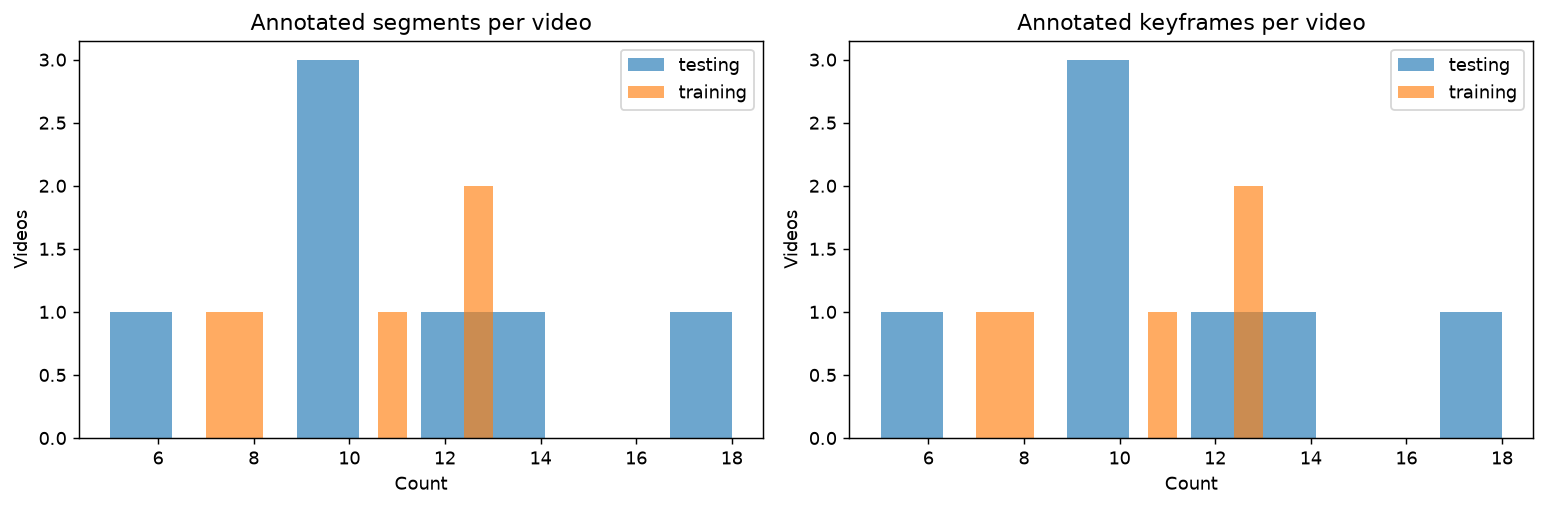

,id,split,segments,keyframes,missing_keyframe_png,orphan_keyframe_png,bad_interval_indices
2,lecture_08,testing,13,13,[],[62553],[]


,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
testing,77.0,7797.8,4413.6,263.0,7347.0,13129.2,19672.0,22430.0
training,52.0,7129.9,4650.5,280.0,6504.0,12047.7,21546.0,23791.0


In [3]:
grouped = ledger.groupby("split", dropna=False).agg(videos=("id", "size"), segments=("segments", "sum"), keyframes=("keyframes", "sum"), keyframe_png=("png_keyframes", "sum")).reset_index()
display(grouped)
display(ledger.groupby("split")[["segments", "keyframes"]].describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, group in ledger.groupby("split"):
    axes[0].hist(group["segments"], bins=10, alpha=.65, label=split)
    axes[1].hist(group["keyframes"], bins=10, alpha=.65, label=split)
for axis, title in zip(axes, ["Annotated segments per video", "Annotated keyframes per video"]):
    axis.set_title(title); axis.set_xlabel("Count"); axis.set_ylabel("Videos"); axis.legend()
plt.tight_layout(); plt.show()
outliers = ledger.loc[(ledger["segments"] == 0) | (ledger["keyframes"] == 0) | ledger["missing_keyframe_png"].map(bool) | ledger["orphan_keyframe_png"].map(bool) | ledger["bad_interval_indices"].map(bool)]
print("Structural outliers:")
display(outliers[["id", "split", "segments", "keyframes", "missing_keyframe_png", "orphan_keyframe_png", "bad_interval_indices"]])
display(segments_df.groupby("split")["frames"].describe(percentiles=[.5,.9,.99]).round(1))


Decoded gallery images: 2 of 130 released keyframe PNGs; original videos decoded: 0


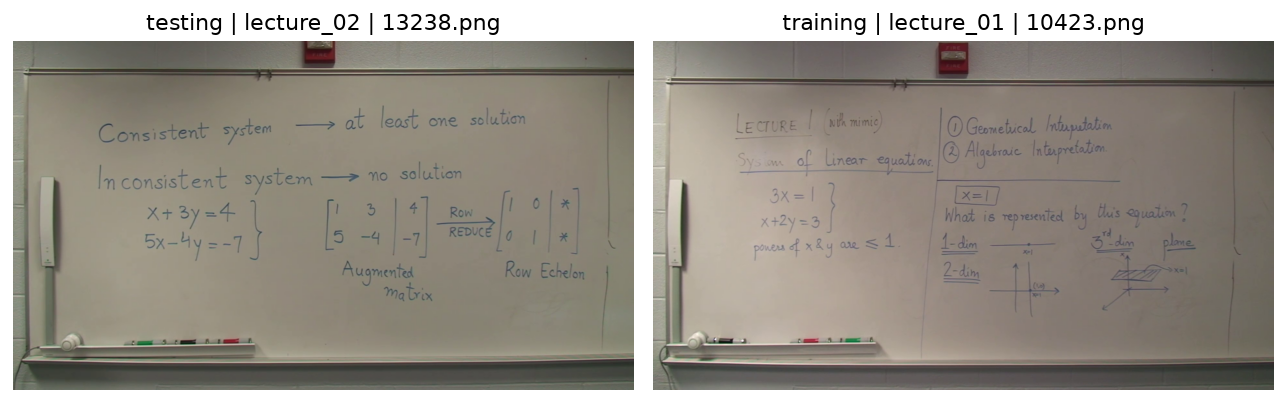

In [4]:
# Deterministic sample: first annotated video per split, first keyframe image by filename.
samples = []
for split, part in ledger.groupby("split", sort=True):
    for lecture_id in part["id"]:
        prefix = annotation_prefix(lecture_id)
        pngs = sorted(p for p in NAMES if p.startswith(prefix + "/keyframes/") and p.lower().endswith(".png"))
        if pngs:
            samples.append((split, lecture_id, pngs[0])); break
fig, axes = plt.subplots(1, max(1, len(samples)), figsize=(5 * max(1, len(samples)), 4))
if len(samples) == 1: axes = [axes]
for axis, (split, lecture_id, name) in zip(axes, samples):
    image = Image.open(io.BytesIO(ZIP.read(name)))
    image.verify()
    image = Image.open(io.BytesIO(ZIP.read(name)))
    axis.imshow(image); axis.set_title(f"{split} | {lecture_id} | {PurePosixPath(name).name}"); axis.axis("off")
if not samples: axes[0].text(.1,.5,"No keyframe PNG in release"); axes[0].axis("off")
plt.tight_layout(); plt.show()
print("Decoded gallery images:", len(samples), "of", int(ledger["png_keyframes"].sum()), "released keyframe PNGs; original videos decoded: 0")


Keyframe PNG decoded: 130 / 130 failed reads: 0
Cross-split dHash candidate pairs (distance <= 4): 0


""


""


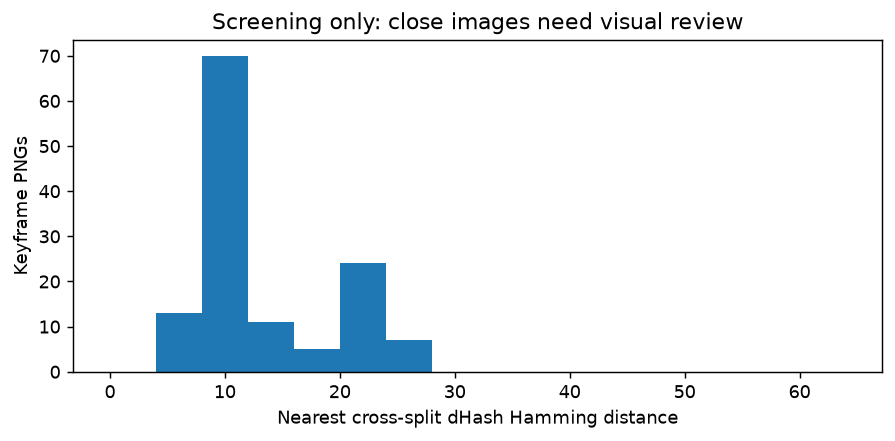

In [5]:
# Decode every released keyframe PNG for a perceptual-hash screening. This is a review queue, not a duplicate verdict.
def dhash(image):
    small = image.convert("L").resize((9, 8))
    values = list(small.get_flattened_data())
    bits = 0
    for y in range(8):
        for x in range(8):
            bits = (bits << 1) | (values[y * 9 + x] > values[y * 9 + x + 1])
    return bits

image_signatures, image_failures = [], []
for row in rows:
    prefix = annotation_prefix(row["id"])
    for name in sorted(p for p in NAMES if p.startswith(prefix + "/keyframes/") and p.lower().endswith(".png")):
        try:
            with Image.open(io.BytesIO(ZIP.read(name))) as image:
                image.load()
                image_signatures.append((row["id"], row["split"], name, dhash(image)))
        except Exception as error:
            image_failures.append({"id": row["id"], "path": name, "error": str(error)})
near_pairs = []
nearest_cross_split = []
for i, left in enumerate(image_signatures):
    other_distances = [(left[3] ^ right[3]).bit_count() for right in image_signatures if left[1] != right[1] and left[0] != right[0]]
    for right in image_signatures[i+1:]:
        if left[1] == right[1] or left[0] == right[0]: continue
        distance = (left[3] ^ right[3]).bit_count()
        if distance <= 4:
            near_pairs.append({"left_id": left[0], "right_id": right[0], "left_png": PurePosixPath(left[2]).name, "right_png": PurePosixPath(right[2]).name, "dhash_distance": distance})
    if other_distances: nearest_cross_split.append(min(other_distances))
print("Keyframe PNG decoded:", len(image_signatures), "/", int(ledger["png_keyframes"].sum()), "failed reads:", len(image_failures))
print("Cross-split dHash candidate pairs (distance <= 4):", len(near_pairs))
display(pd.DataFrame(near_pairs).head(30))
display(pd.DataFrame(image_failures))
if near_pairs:
    image_by_id_and_name = {(item[0], PurePosixPath(item[2]).name): item[2] for item in image_signatures}
    first_pairs = sorted(near_pairs, key=lambda item: (item["dhash_distance"], item["left_id"], item["right_id"]))[:2]
    fig, axes = plt.subplots(len(first_pairs), 2, figsize=(10, 4 * len(first_pairs)), squeeze=False)
    for row_index, candidate in enumerate(first_pairs):
        for col, side in enumerate(("left", "right")):
            image_path = image_by_id_and_name[(candidate[f"{side}_id"], candidate[f"{side}_png"])]
            with Image.open(io.BytesIO(ZIP.read(image_path))) as image:
                axes[row_index, col].imshow(image.copy())
            axes[row_index, col].set_title(f"{candidate[f'{side}_id']} / {candidate[f'{side}_png']}")
            axes[row_index, col].axis("off")
    fig.suptitle("dHash candidates for human review; similarity is not duplicate proof")
    plt.tight_layout(); plt.show()
if nearest_cross_split:
    plt.figure(figsize=(7, 3.5)); plt.hist(nearest_cross_split, bins=range(0, 66, 4)); plt.xlabel("Nearest cross-split dHash Hamming distance"); plt.ylabel("Keyframe PNGs"); plt.title("Screening only: close images need visual review"); plt.tight_layout(); plt.show()


## EDA nhận xét

Toàn bộ 12/12 video có annotation và 130/130 PNG giải mã được. `lecture_08` (test) có ảnh keyframe 62553.png không được tham chiếu bởi chỉ số keyframe trong XML: giữ trong ledger, không tự thêm nhãn. Không thấy ảnh trùng chính xác hoặc cặp dHash ≤4 giữa train/test. Đây là kết quả sàng lọc ảnh được phát hành, không suy ra video gốc không trùng.

In [6]:
bad = ledger.loc[(~ledger["metadata_present"]) | (~ledger["segments_xml"]) | (ledger["keyframes"] == 0) | ledger["missing_keyframe_png"].map(bool) | ledger["orphan_keyframe_png"].map(bool) | ledger["bad_interval_indices"].map(bool), "id"].tolist()
image_hashes = defaultdict(list)
for row in rows:
    prefix = annotation_prefix(row["id"])
    for name in NAMES:
        if name.startswith(prefix + "/keyframes/") and name.lower().endswith(".png"):
            image_hashes[hashlib.sha256(ZIP.read(name)).hexdigest()].append((row["id"], row["split"], name))
duplicate_keyframes = {digest: refs for digest, refs in image_hashes.items() if len(refs) > 1}
cross_split_keyframe_duplicates = {digest: refs for digest, refs in duplicate_keyframes.items() if len({ref[1] for ref in refs}) > 1}
source_overlap = {s: sorted({x for x in part["source_id"] if x} & {x for x in ledger.loc[ledger["split"] != s, "source_id"] if x}) for s,part in ledger.groupby("split")}
source_link_overlap = {s: sorted({x for x in part["source_link"] if x} & {x for x in ledger.loc[ledger["split"] != s, "source_link"] if x}) for s,part in ledger.groupby("split")}
video_link_counts = Counter(x for links in ledger["video_file_links"] for x in links)
reused_video_paths = {k:v for k,v in video_link_counts.items() if v > 1}
decision = {
    "source_ids": len(source_ids), "annotated_ids": len(annotation_ids), "missing_annotation_ids": missing_annotation_ids,
    "extra_annotation_ids": extra_annotation_ids, "structural_bad_ids": bad,
    "source_group_id_cross_split_overlap_review_signal": source_overlap,
    "exact_source_link_cross_split_overlap": source_link_overlap, "reused_video_paths": reused_video_paths,
    "keyframe_pngs": int(ledger["png_keyframes"].sum()), "exact_duplicate_keyframe_groups": len(duplicate_keyframes),
    "cross_split_exact_keyframe_groups": len(cross_split_keyframe_duplicates), "decoded_sample_pngs": len(samples), "original_videos_decoded": 0,
    "decoded_all_keyframe_pngs_for_dhash": len(image_signatures), "keyframe_png_read_failures": image_failures,
    "cross_split_dhash_candidates_le4": len(near_pairs), "dhash_candidate_video_ids": sorted({x["left_id"] for x in near_pairs} | {x["right_id"] for x in near_pairs}),
    "test_references_seen": bool(split_members.get("testing")),
    "decision": "HOLD for formal required-state benchmark: annotation package inspected, but original video media and semantic required-state interpretation not audited."
}
print(json.dumps(decision, ensure_ascii=False, indent=2))


{
  "source_ids": 12,
  "annotated_ids": 12,
  "missing_annotation_ids": [],
  "extra_annotation_ids": [],
  "structural_bad_ids": [
    "lecture_08"
  ],
  "source_group_id_cross_split_overlap_review_signal": {
    "testing": [],
    "training": []
  },
  "exact_source_link_cross_split_overlap": {
    "testing": [],
    "training": []
  },
  "reused_video_paths": {},
  "keyframe_pngs": 130,
  "exact_duplicate_keyframe_groups": 0,
  "cross_split_exact_keyframe_groups": 0,
  "decoded_sample_pngs": 2,
  "original_videos_decoded": 0,
  "decoded_all_keyframe_pngs_for_dhash": 130,
  "keyframe_png_read_failures": [],
  "cross_split_dhash_candidates_le4": 0,
  "dhash_candidate_video_ids": [],
  "test_references_seen": true,
  "decision": "HOLD for formal required-state benchmark: annotation package inspected, but original video media and semantic required-state interpretation not audited."
}


## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

In [7]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "accessmath", "observed_at_utc": "2026-10-10T08:58:01.914738+00:00", "counts": {"selected": 12, "observed": 12, "label_valid": 11, "media_valid": 0, "evaluated": 0, "failed": 0, "unit": "annotated video", "label_valid_definition": "structural annotation only; not independent task GT", "media_valid_definition": "original source videos verified for target endpoint", "failed_definition": "record read/parse failures; HOLD is not a processing failure"}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-id-ledger.csv", "sha256": "802445eb5df29d49690414bc55d6e23908d67c588d05493b610aa151cafcb4c7", "rows": 12}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-segment-ledger.csv", "sha256": "d98daeaebc8ce5bc33f064a0eaf2e11e142c4c5b3a50955455a4c0faa734ff4b", "rows": 129}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-source-group-ledger.csv", "sha256": "7eb70257593da06f682a3ddda54a9d260d4fc514f645237f5ca74b08f8da61a6", "rows": 0}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-historical-notebook-decision.json", "sha256": "0194d38f3a436d6b8f1a1d0e3eb3bdb67516a8458bf3bd6fa585ef7705187dbb"}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-keyframe-ledger.csv", "sha256": "848da0a1cf8eff897ff5d4503a632fcad8acdd90f16fae462bad1ae374f0f708", "rows": 129}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-lecturemath-source-bridge-ledger.csv", "sha256": "017ba640dab0564a0abee4a375ca4c868b235097761e3aea6648cd21a0e48744", "rows": 12}], "model_inference_run": false, "unseen_reference_claim": false, "source": {"path": "experiments\\\\outputs\\\\board_eda_downloads\\\\accessmath-official-2017.zip", "sha256": "7bffabf04ecf5ee5c03fb36089dba81bbef8c6a0f310002207df6ed51bfd9fee"}, "keyframe_records": 129, "released_pngs": 130, "original_media_decoded_this_followup": 0, "image_decoding_rerun": false, "historical_evidence": [{"source_ids": 12, "annotated_ids": 12, "missing_annotation_ids": [], "extra_annotation_ids": [], "structural_bad_ids": ["lecture_08"], "source_group_id_cross_split_overlap_review_signal": {"testing": [], "training": []}, "exact_source_link_cross_split_overlap": {"testing": [], "training": []}, "reused_video_paths": {}, "keyframe_pngs": 130, "exact_duplicate_keyframe_groups": 0, "cross_split_exact_keyframe_groups": 0, "decoded_sample_pngs": 2, "original_videos_decoded": 0, "decoded_all_keyframe_pngs_for_dhash": 130, "keyframe_png_read_failures": [], "cross_split_dhash_candidates_le4": 0, "dhash_candidate_video_ids": [], "test_references_seen": true, "decision": "HOLD for formal required-state benchmark: annotation package inspected, but original video media and semantic required-state interpretation not audited."}], "frozen": false, "endpoint": "released keyframe/summary annotation diagnostics; required board-state endpoint HOLD", "blocker": "Original video, edit/multipart timebase, source dependence and required-state label semantics unresolved.", "source_probes": [{"dataset": "accessmath", "label": "official-project-page", "url": "https://www.cs.rit.edu/~rlaz/Projects/AccessMath.html", "observed_at_utc": "2026-10-10T08:59:07.999045+00:00", "status": 404, "final_url": "https://www.cs.rit.edu/~rlaz/Projects/AccessMath.html", "sha256": "59086cc58cbdd515bed2645bf99f2de91d7cbf6bcaf36a5f58a22c9b235e881f", "bytes": 277, "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\accessmath-official-project-page.txt"}, {"dataset": "accessmath", "label": "potential-official-source-bridge", "source_url": "https://www.youtube.com/watch?v=6arlCAT3Hb4", "lecturemath_id": "00000_000_001", "source_group": "00000", "decision": "HOLD", "reason": "LectureMath released source 00000 references AccessMath; multipart camera timebase not verified"}], "media_probe_limit": "Bounded deterministic source probes only; no full availability survey or original media decode.", "bounded_media_samples": [], "source_aligned_media_valid": 0, "time_unit_review": {"status": "verified_from_author_code", "unit": "milliseconds", "sources": [{"dataset": "lecturemath", "label": "keyframe-code", "url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AccessMath/annotation/keyframe_annotation.py", "observed_at_utc": "2026-10-10T09:01:29.180900+00:00", "status": 200, "final_url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AccessMath/annotation/keyframe_annotation.py", "sha256": "4f6f19aecb5aeb4a4f36eaaa788e6f4905220adadd4d51514bcc15c363a9a447", "bytes": 23484, "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lecturemath-keyframe-code.txt"}, {"dataset": "lecturemath", "label": "keyframe-extractor-code", "url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AccessMath/preprocessing/content/keyframe_extractor.py", "observed_at_utc": "2026-10-10T09:01:29.700005+00:00", "status": 200, "final_url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AccessMath/preprocessing/content/keyframe_extractor.py", "sha256": "0c5ea127cbaf4c54b381291bafc84563bf1e7f3cc500ddf8f2a6596a69685948", "bytes": 10150, "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lecturemath-keyframe-extractor-code.txt"}, {"dataset": "lecturemath", "label": "timehelper-code", "url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AM_CommonTools/util/time_helper.py", "observed_at_utc": "2026-10-10T09:01:30.186498+00:00", "status": 200, "final_url": "https://raw.githubusercontent.com/kdavila/lecturemath/245d58a20393166addacb9ece75326ef3455b16f/ACCESS2021_release/AM_CommonTools/util/time_helper.py", "sha256": "4a188d18f7e2f926e5c0af498d1c509721d32c2dcf9f93d9cf4b37a6e2686a0c", "bytes": 2313, "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lecturemath-timehelper-code.txt"}], "media_alignment": "HOLD; author annotation clock is not proof of downloaded video clock"}, "label_semantics_review": "Released extractive keyframes, segments and handwritten-content annotations; not independently verified required board-state GT.", "cross_dataset_source_bridge_candidates": 12, "cross_dataset_leakage": "Potential author-title source reuse across datasets; no independent-source claim until media alignment."}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/accessmath-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '53ba72e5b4004d9a67c554cea0ecaef02311a14cf5d7e6e216e79f61b6996f4e', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))


**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed,unit,label_valid_definition,media_valid_definition,failed_definition
0,12,12,11,0,0,0,annotated video,structural annotation only; not independent ta...,original source videos verified for target end...,record read/parse failures; HOLD is not a proc...


**Status:** HOLD; cohort not frozen

,field,value
0,dataset,"""accessmath"""
1,observed_at_utc,"""2026-10-10T08:58:01.914738+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,source,"{""path"": ""experiments\\outputs\\board_eda_down..."
5,keyframe_records,129
6,released_pngs,130
7,original_media_decoded_this_followup,0
8,image_decoding_rerun,false
9,historical_evidence,"[{""source_ids"": 12, ""annotated_ids"": 12, ""miss..."


Evidence: `experiments/outputs/dataset_qualification_261010/accessmath-id-ledger.csv` · SHA-256 `802445eb5df29d49690414bc55d6e23908d67c588d05493b610aa151cafcb4c7`

12 ledger rows; first 20 shown below. Full ledger remains linked above.

... (9 outputs left out)

Evidence: `experiments/outputs/dataset_qualification_261010/accessmath-lecturemath-source-bridge-ledger.csv` · SHA-256 `017ba640dab0564a0abee4a375ca4c868b235097761e3aea6648cd21a0e48744`

12 ledger rows; first 20 shown below. Full ledger remains linked above.

,accessmath_id,lecturemath_id,accessmath_split,lecturemath_split,source_url,official_raw_title,title_mapping_evidence,decision,reason
0,nm_lecture_01,00000_000_001,training,training,https://www.youtube.com/watch?v=6arlCAT3Hb4,AccessMath - NM Lecture 01,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
1,nm_lecture_02,00000_000_002,testing,testing,https://www.youtube.com/watch?v=AsDfluoYB4Q,AccessMath - NM Lecture 02,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
2,nm_lecture_03,00000_000_003,training,training,https://www.youtube.com/watch?v=iggO022ncy8,AccessMath - NM Lecture 03,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
3,nm_lecture_05,00000_000_005,testing,testing,https://www.youtube.com/watch?v=ar1eRRoRYBo,AccessMath - NM Lecture 05,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
4,lecture_01,00000_001_001,training,training,https://www.youtube.com/watch?v=Gyagxo3UTXo,AccessMath - Lecture 01,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
5,lecture_02,00000_001_002,testing,testing,https://www.youtube.com/watch?v=MDvbJi9X_XU,AccessMath - Lecture 02,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
6,lecture_06,00000_001_006,training,training,https://www.youtube.com/watch?v=YW8b2Nvt9dE,AccessMath - Lecture 06,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
7,lecture_07,00000_001_007,testing,testing,https://www.youtube.com/watch?v=SuWuHp0ZjPk,AccessMath - Lecture 07,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
8,lecture_08,00000_001_008,testing,testing,https://www.youtube.com/watch?v=7D8-R-4Cdfg,AccessMath - Lecture 08,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...
9,lecture_10,00000_001_010,testing,testing,https://www.youtube.com/watch?v=TtS5EG8Dc-E,AccessMath - Lecture 10,author metadata exact dataset/lecture title; o...,HOLD,potential_cross_dataset_reuse;do_not_pool_as_i...


**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**